In [52]:
import numpy as np
import pandas as pd

%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

In [65]:
cell_type = "856"
sheet = cell_type + "_script"
folder_path = "/Users/mariaclaudia/Documents/Lab/Experiments/Calcium/Fura 2/"
file_name = "Fura2 FASN KD_paper.xlsx"
Ca_traces = pd.read_excel(folder_path + file_name, sheet_name=sheet)  # Replace with actual filename
print(Ca_traces.head())

       NT-1    NT-1.1    NT-1.2    NT-1.3    NT-1.4      KD-1    KD-1.1  \
0 -9.974200 -8.572955 -7.423522 -2.556181  1.570951 -1.525624  3.950158   
1 -9.265380 -7.754694 -7.302263 -1.789954  1.550025 -2.332301  4.222663   
2 -8.709861 -7.452669 -6.933910 -1.147649  1.842755 -0.861832  4.465694   
3 -8.690523 -7.382371 -7.885388 -1.350509  1.908289 -1.948627  6.122488   
4 -9.352961 -7.732553 -7.078290 -2.374667  2.004885 -1.405486  4.316269   

     KD-1.2    KD-1.3    KD-1.4  ...   NT-2.14    KD-2.5    KD-2.6    KD-2.7  \
0  3.589466  4.804760  4.471626  ...  1.313511  1.360408  1.295170  1.378979   
1  3.210276  5.553704  4.050818  ...  1.299261  1.384273  1.280308  1.359109   
2  3.591101  5.505686  4.663276  ...  1.332558  1.404625  1.298549  1.428747   
3  2.931513  5.090483  5.213050  ...  1.341037  1.397986  1.278293  1.387531   
4  3.032265  5.867360  4.318605  ...  1.311710  1.386246  1.278127  1.400783   

     KD-2.8    KD-2.9   KD-2.10   KD-2.11   KD-2.12   KD-2.13  
0  1

In [66]:
Ca_traces.rename(
    columns={**{col: "NT" for col in Ca_traces.columns if "NT" in col},
             **{col: "KD" for col in Ca_traces.columns if "KD" in col}},
    inplace=True
)
print(Ca_traces.head())



         NT        NT        NT        NT        NT        KD        KD  \
0 -9.974200 -8.572955 -7.423522 -2.556181  1.570951 -1.525624  3.950158   
1 -9.265380 -7.754694 -7.302263 -1.789954  1.550025 -2.332301  4.222663   
2 -8.709861 -7.452669 -6.933910 -1.147649  1.842755 -0.861832  4.465694   
3 -8.690523 -7.382371 -7.885388 -1.350509  1.908289 -1.948627  6.122488   
4 -9.352961 -7.732553 -7.078290 -2.374667  2.004885 -1.405486  4.316269   

         KD        KD        KD  ...        NT        KD        KD        KD  \
0  3.589466  4.804760  4.471626  ...  1.313511  1.360408  1.295170  1.378979   
1  3.210276  5.553704  4.050818  ...  1.299261  1.384273  1.280308  1.359109   
2  3.591101  5.505686  4.663276  ...  1.332558  1.404625  1.298549  1.428747   
3  2.931513  5.090483  5.213050  ...  1.341037  1.397986  1.278293  1.387531   
4  3.032265  5.867360  4.318605  ...  1.311710  1.386246  1.278127  1.400783   

         KD        KD        KD        KD        KD        KD  
0  1

In [67]:
# Define the statistics
def stat (g1, g2):
    g_av1 = g1.mean(1)
    g_av2 = g2.mean(1)
    diff = g_av2 - g_av1
    L2_dist = np.sqrt(np.sum (diff**2))
    return L2_dist


In [68]:
# Run the statitics on the dataset
Ca_NT = Ca_traces["NT"]
Ca_KD = Ca_traces["KD"]

data_L2 = stat(Ca_NT, Ca_KD)

In [69]:
# Simulate data
sim_L2 = []
permutations = 3300
#print(Ca_traces.columns.to_series())
for i in range(permutations):
    shuffled_labels = Ca_traces.columns.to_series().sample(n=len(Ca_traces.columns), random_state=i)
    shuffled_df = Ca_traces.copy()
    shuffled_df.columns = shuffled_labels
    #print(shuffled_df.head())
    sim_NT = shuffled_df["NT"]
    sim_KD = shuffled_df["KD"]
    sim_L2.append(stat(sim_NT, sim_KD))
    if sim_L2[i] > data_L2+10:
        problematic = shuffled_df

In [70]:
problematic.columns

Index(['NT', 'KD', 'NT', 'KD', 'KD', 'NT', 'NT', 'KD', 'NT', 'KD', 'KD', 'NT',
       'NT', 'NT', 'NT', 'NT', 'KD', 'NT', 'NT', 'KD', 'NT', 'KD', 'KD', 'NT',
       'KD', 'NT', 'KD', 'KD', 'KD', 'NT', 'NT', 'NT', 'KD', 'KD', 'KD', 'NT',
       'NT', 'NT', 'NT', 'KD', 'KD', 'NT', 'KD', 'KD', 'KD', 'KD', 'KD', 'KD',
       'NT', 'KD', 'KD', 'NT', 'NT', 'KD', 'NT', 'NT'],
      dtype='object')

In [71]:
Ca_traces.columns

Index(['NT', 'NT', 'NT', 'NT', 'NT', 'KD', 'KD', 'KD', 'KD', 'KD', 'KD', 'KD',
       'KD', 'KD', 'KD', 'NT', 'NT', 'NT', 'NT', 'NT', 'NT', 'NT', 'NT', 'NT',
       'NT', 'NT', 'NT', 'NT', 'KD', 'KD', 'KD', 'KD', 'KD', 'KD', 'KD', 'KD',
       'KD', 'NT', 'NT', 'NT', 'NT', 'NT', 'NT', 'NT', 'NT', 'NT', 'NT', 'KD',
       'KD', 'KD', 'KD', 'KD', 'KD', 'KD', 'KD', 'KD'],
      dtype='object')

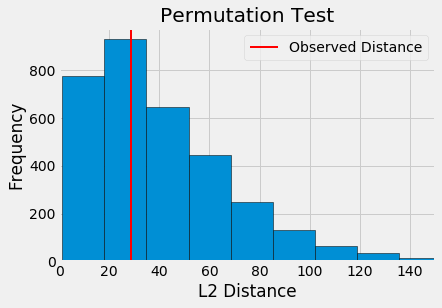

In [72]:
# Plot results
plt.hist(sim_L2, bins=10, edgecolor='black')
plt.axvline(data_L2, color='red', linewidth=2, label='Observed Distance')
plt.title("Permutation Test")
plt.xlabel("L2 Distance")
plt.ylabel("Frequency")
plt.legend()
plt.xlim([0, 150])
plt.show()

In [73]:
p_value = sum(sim_L2 >= data_L2)/permutations
p_value

0.5696969696969697